# MPPT Optimal Duty Cycle Prediction Using ANN

**Project:** Deep Learning-based MPPT for a solar panel

This notebook follows the structure of the sample ANN regression notebook, adapted to `mppt_4sensor_dataset.csv`. The model uses four input features and predicts `Optimal_Duty`.

## 1. Load the dataset
Keep `mppt_4sensor_dataset.csv` in the same folder as this notebook.

In [116]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dataset_file = "mppt_singlediode_dataset.csv"
df = pd.read_csv(dataset_file)
print(f"Loaded dataset from: {dataset_file}")
print("Dataset shape:", df.shape)
df.head()

Loaded dataset from: mppt_singlediode_dataset.csv
Dataset shape: (3000, 5)


,Irradiance,Temperature,V_pv,I_pv,Optimal_Duty
0,796.56044,34.74953,21.19290,6.46913,0.78284
1,727.63123,19.23798,32.90941,4.57308,0.76516
2,978.06012,49.25129,26.99538,7.22238,0.80994
3,215.30227,35.26737,27.26114,1.54371,0.58514
4,433.71822,56.70442,26.20985,3.06219,0.72080


In [117]:
# Check column names, data types, missing values, and duplicate rows
print(df.columns.tolist())
print(df.info())
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
df.describe()

['Irradiance', 'Temperature', 'V_pv', 'I_pv', 'Optimal_Duty']
<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Irradiance    3000 non-null   float64
 1   Temperature   3000 non-null   float64
 2   V_pv          3000 non-null   float64
 3   I_pv          3000 non-null   float64
 4   Optimal_Duty  3000 non-null   float64
dtypes: float64(5)
memory usage: 117.3 KB
None
Missing values:
 Irradiance      0
Temperature     0
V_pv            0
I_pv            0
Optimal_Duty    0
dtype: int64
Duplicate rows: 0


,Irradiance,Temperature,V_pv,I_pv,Optimal_Duty
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.00000
mean,544.883921,37.341261,21.792709,4.036844,0.70628
std,261.655243,12.883109,6.689614,2.102556,0.09576
min,100.742160,15.014150,8.606640,0.304870,0.36988
25%,313.013778,26.444690,16.101443,2.167667,0.65671
50%,542.052670,37.211520,21.750990,3.873180,0.73857
75%,774.799803,48.377538,27.329725,5.772670,0.78152
max,999.874760,59.998970,36.470190,8.246630,0.81614


## 2. Exploratory Data Analysis (EDA)

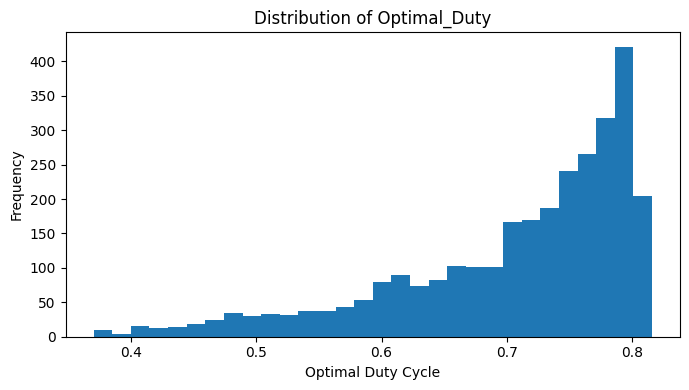

In [118]:
# Visualize the target variable
plt.figure(figsize=(7, 4))
plt.hist(df["Optimal_Duty"], bins=30)
plt.xlabel("Optimal Duty Cycle")
plt.ylabel("Frequency")
plt.title("Distribution of Optimal_Duty")
plt.tight_layout()
plt.show()

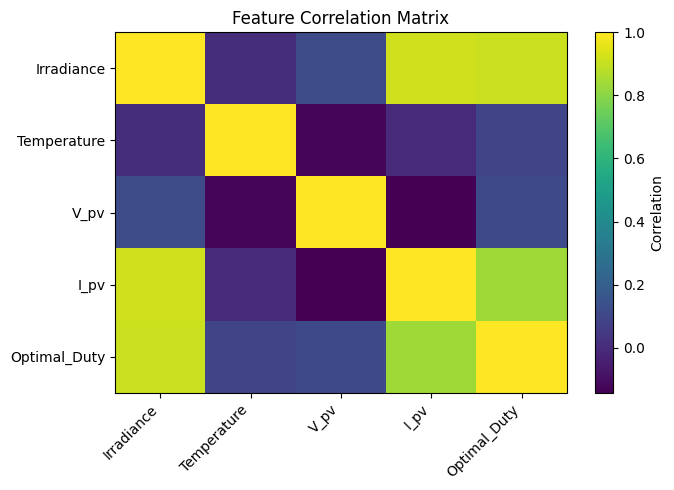

In [119]:
# Correlation between the dataset columns
plt.figure(figsize=(7, 5))
plt.imshow(df.corr(numeric_only=True), aspect="auto")
plt.xticks(range(len(df.columns)), df.columns, rotation=45, ha="right")
plt.yticks(range(len(df.columns)), df.columns)
plt.colorbar(label="Correlation")
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

## 3. Separate features (X) and target (y)

The four inputs are `Irradiance`, `Temperature`, `V_pv`, and `I_pv`. The target is `Optimal_Duty`. This dataset therefore trains the ANN to predict duty cycle, **not Vmpp voltage**.

In [120]:
feature_columns = ["Irradiance", "Temperature", "V_pv", "I_pv"]
target_column = "Optimal_Duty"

X = df[feature_columns]
y = df[target_column]

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("Input features:", feature_columns)
print("Target:", target_column)

Input shape: (3000, 4)
Target shape: (3000,)
Input features: ['Irradiance', 'Temperature', 'V_pv', 'I_pv']
Target: Optimal_Duty


## 4. Split data into training, validation, and testing sets (80/10/10)

In [121]:
from sklearn.model_selection import train_test_split

# First separate 10% for final testing
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.10, random_state=42
)

# From the remaining 90%, take 1/9 (10% of the full dataset) for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=1/9, random_state=42
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 2400
Validation samples: 300
Testing samples: 300


## 5. Normalize the input data

Fit the scaler only on training data to avoid data leakage, then apply it to validation and test data.

In [122]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train_norm = scaler.fit_transform(X_train)
X_val_norm = scaler.transform(X_val)
X_test_norm = scaler.transform(X_test)

print("Normalized training shape:", X_train_norm.shape)

Normalized training shape: (2400, 4)


## 6. Build the 4-16-8-1 ANN model

- 4 input features
- Hidden layer 1: 16 neurons
- Hidden layer 2: 8 neurons
- 1 output neuron for predicted duty cycle

This is a regression problem, so the output layer uses a linear activation.

In [123]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(4,), name="Input_Layer"),
    Dense(16, activation="relu", name="Hidden1"),
    Dense(8, activation="relu", name="Hidden2"),
    Dense(1, activation="linear", name="Output_Optimal_Duty")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Hidden1 (Dense)                 │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Optimal_Duty (Dense)     │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225 (900.00 B)

 Trainable params: 225 (900.00 B)

 Non-trainable params: 0 (0.00 B)

## 7. Train the ANN

In [124]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

history = model.fit(
    X_train_norm, y_train,
    validation_data=(X_val_norm, y_val),
    epochs=200,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.7008 - mae: 0.7837 - val_loss: 0.2188 - val_mae: 0.4594
Epoch 2/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 923us/step - loss: 0.0875 - mae: 0.2669 - val_loss: 0.0139 - val_mae: 0.1027
Epoch 3/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 940us/step - loss: 0.0076 - mae: 0.0758 - val_loss: 0.0061 - val_mae: 0.0673
Epoch 4/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 988us/step - loss: 0.0049 - mae: 0.0606 - val_loss: 0.0044 - val_mae: 0.0573
Epoch 5/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 832us/step - loss: 0.0036 - mae: 0.0514 - val_loss: 0.0034 - val_mae: 0.0499
Epoch 6/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 842us/step - loss: 0.0029 - mae: 0.0451 - val_loss: 0.0028 - val_mae: 0.0450
Epoch 7/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 772us/step - loss: 0.0025 - mae: 0.0411 - val_loss: 0.0025 - val_mae: 0.0417
Epoch 8/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 940us/step - loss: 0.0023 - mae: 0.0386 - val_loss: 0.0023 - val_mae: 0.0395
Epoch 9/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 930us/st

## 8. Plot training and validation loss

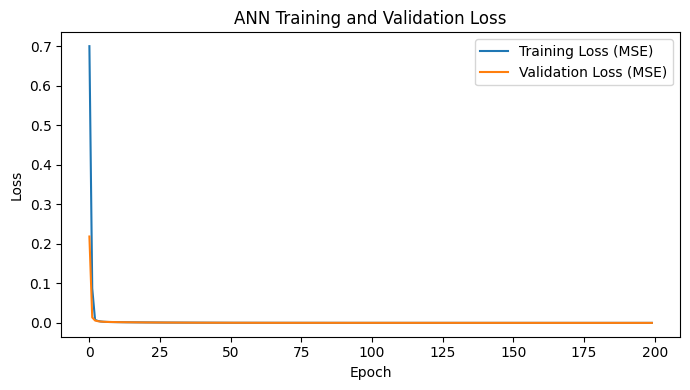

In [125]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training Loss (MSE)")
plt.plot(history.history["val_loss"], label="Validation Loss (MSE)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN Training and Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

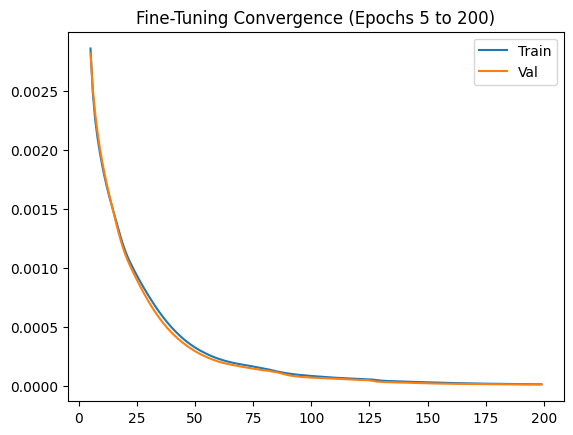

In [132]:
# View epochs 5 to 200:
plt.plot(range(5, 200), history.history["loss"][5:], label="Train")
plt.plot(range(5, 200), history.history["val_loss"][5:], label="Val")
plt.title("Fine-Tuning Convergence (Epochs 5 to 200)")
plt.legend()
plt.show()

## 9. Evaluate on unseen test data

MAE tells the average absolute prediction error; MSE penalizes larger errors more strongly.

In [126]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = model.predict(X_test_norm).ravel()

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Test MAE:  {mae:.6f}")
print(f"Test MSE:  {mse:.6f}")
print(f"Test RMSE: {rmse:.6f}")
print(f"Test R²:   {r2:.6f}")

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Test MAE:  0.003130
Test MSE:  0.000019
Test RMSE: 0.004370
Test R²:   0.997720


## 10. Compare actual and predicted duty cycle

In [127]:
comparison = pd.DataFrame({
    "Actual_Optimal_Duty": y_test.to_numpy(),
    "Predicted_Optimal_Duty": y_pred
})
comparison["Absolute_Error"] = abs(
    comparison["Actual_Optimal_Duty"] - comparison["Predicted_Optimal_Duty"]
)
comparison.head(15)

,Actual_Optimal_Duty,Predicted_Optimal_Duty,Absolute_Error
0,0.72149,0.726283,0.004793
1,0.79275,0.792829,0.000079
2,0.73550,0.734176,0.001324
3,0.75900,0.758117,0.000883
4,0.77416,0.773033,0.001127
5,0.81297,0.819903,0.006933
6,0.79131,0.791571,0.000261
7,0.70080,0.694392,0.006408
8,0.80247,0.804565,0.002095
9,0.77826,0.776384,0.001876


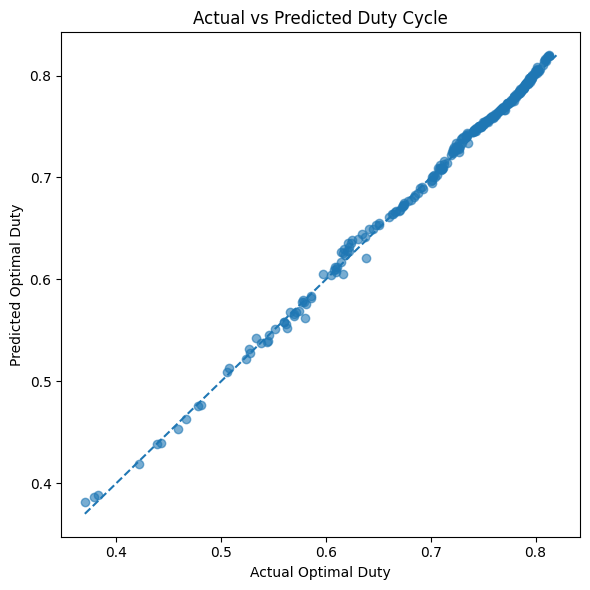

In [128]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
low = min(float(y_test.min()), float(y_pred.min()))
high = max(float(y_test.max()), float(y_pred.max()))
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual Optimal Duty")
plt.ylabel("Predicted Optimal Duty")
plt.title("Actual vs Predicted Duty Cycle")
plt.tight_layout()
plt.show()

## 11. Save the trained model and input scaler

In [129]:
import joblib

model.save("mppt_ann_4_16_8_1.keras")
joblib.dump(scaler, "mppt_input_scaler.pkl")
print("Saved model: mppt_ann_4_16_8_1.keras")
print("Saved scaler: mppt_input_scaler.pkl")

Saved model: mppt_ann_4_16_8_1.keras
Saved scaler: mppt_input_scaler.pkl


## 12. Predict duty cycle for one new sample

Replace the example values with real sensor readings in the same column order.

In [130]:
new_sample = pd.DataFrame([{
    "Irradiance": 800,
    "Temperature": 35,
    "V_pv": 17.0,
    "I_pv": 2.0
}])

new_sample_norm = scaler.transform(new_sample[feature_columns])
predicted_duty = model.predict(new_sample_norm, verbose=0)[0, 0]
print(f"Predicted Optimal Duty Cycle: {predicted_duty:.4f}")

Predicted Optimal Duty Cycle: 0.7824


In [131]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict on normalized test features
y_pred = model.predict(X_test_norm).flatten()
y_actual = np.asarray(y_test).flatten()

mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
r2 = r2_score(y_actual, y_pred)

print("Test MAE:", mae)
print("Test RMSE:", rmse)
print("Test R2 Score:", r2)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 966us/step
Test MAE: 0.0031304386327107754
Test RMSE: 0.004369980097930065
Test R2 Score: 0.997720408566347


## Important notes

1. The CSV currently contains **2,736 rows and 5 columns** (four inputs plus one target).
2. The provided project proposal specifies an 80/10/10 train-validation-test split, MSE loss, Adam optimizer, and MAE evaluation; this notebook follows that plan.
3. The target in this CSV is `Optimal_Duty`. Do not describe this model as predicting `Vmpp` unless you use a dataset whose target column is actually Vmpp.
4. A low test error on this dataset does not by itself prove faster real-world MPPT tracking. That requires comparison against a baseline such as P&O and, ideally, hardware/simulation validation.
5. Run the notebook from top to bottom. If TensorFlow is missing, install it in your notebook environment with `%pip install tensorflow scikit-learn joblib matplotlib pandas`.